# Hälsoanalys

**Data:** Dataset (CSV): health_study_dataset.csv. Kolumner: age (år), sex (M/F), height (cm), weight (kg), systolic_bp (mmHg), cholesterol (mmol/L), smoker (Yes/No), disease (0/1).

#### Slutsats och rekommendation

**Beskrivande analys:** Det systoliska blodtrycket är ungefär normalfördelat. Grupperna rökare och icke-rökare har olika storlek. 73,4% röker och 26,6% röker inte av de 800 som undersökts. 

**Simulering** av andelen personer i datasetet som har sjukdomen med binomialfördelning. Den simulerade sjukandelen på 5,6% ligger nära den verkliga andelen i studien på 5,9%.

**Konfidensintervall** för blodtryckets medelvärde med bootstrap och normalapproximation. De två intervallens nedre och övre gränser är mycket lika och tyder det på att metoderna ger ungefär samma uppskattning av osäkerheten. Båda metoderna ger 95%-igt konfidensintervall på 148-150 mmHg. Stickprovets medelvärde är 149,18 mmHg. Intervallet är ganska smalt och det kan tyda på att skattningen är nära populationens medelvärde. 
 
**Hypotesprövning** ”Rökare har högre medel-blodtryck än icke-rökare”: Det genomsnittliga systoliska blodtrycket var 149,53 mmHg hos rökare och 149,05 mmHg hos icke-rökare. Skillnaden mellan gruppernas medelvärden är liten, ca 0,47mmHg. Resultatet av ensidigt Welch t-test visar inte något statistiskt signifikant stöd för att rökning är förknippat med ett högre systoliskt blodtryck.

**Power:** Simulering görs med Welch t-test för att undersöka hur säkert hypotestestet är. Skillnaden mellan gruppernas medelvärden var 0,47mmHg. Vid den simulerade effektstorleken på 0,47mmHg blev power 11,95%. Det innebär att en effekt av den storleken skulle upptäckas i ungefär 12% av simuleringarna. Med andra ord är det 88 procents risk att testet inte upptäcker skillnaden trots att den faktiskt finns.

**Multipel linjär regression:** Resultatet av den multipla linjära regressionen visar att ålder, kolesterol och vikt tillsammans kan förklara en del av variationen i blodtrycket. Modellen förklarar 42,2 % av variationen, vilket innebär att det finns andra faktorer som också påverkar blodtrycket. Det visar på ett samband mellan variablerna, men inte på ett orsakssamband.

**PCA:** PCA-analysen visar att det går att minska antalet från fem till tre huvudkomponenter samtidigt som 83,0 % av informationen i datan behålls. Huvudkomponenterna fångar olika mönster i data där ålder, kolesterol och blodtryck främst bidrar till PC1, respektive längd och vikt främst bidrar till PC2. PC3 påverkas mest av längd, kolesterol och vikt. Däremot visar de två första huvudkomponenterna ingen tydlig gruppering av observationerna.

**Rekommendation:** Ett större underlag behövs för en mer tillförlitlig analys av skillnaderna i medelblodtryck hos rökare och icke-rökare. Regressionsmodellens förklaringsgrad skulle eventuellt kunna förbättras genom att lägga till fler relevanta variabler. 

In [55]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Sätt seed för reproducerbarhet
np.random.seed(42)

# Konfiguration
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.dpi"] = 120
np.set_printoptions(precision=3)
pd.set_option("display.precision", 3)
plt.style.use("seaborn-v0_8-whitegrid")

### Hämtar in och kontrollerar datakvalitet

In [56]:
# Läser in data
df_raw = pd.read_csv("data/health_study_dataset.csv")

display(df_raw.head())
display(df_raw.info())
# Kontrollerar om det finns NaN
display(df_raw.isna().sum())
display(df_raw.describe())

# Kontrollerar om det finns dubletter
duplicated_count = df_raw.duplicated(keep=False).sum()
print("Antal dubletter:", duplicated_count)

# Dubbelkollar genom att printa unika
print("Antal unika värden:", df_raw.nunique())

valid_values = {
    "disease": [0, 1],
    "smoker": ["No", "Yes"],
    "sex": ["F", "M"]
}

invalid_counts = {}

for col, valid in valid_values.items():
    invalid_mask = ~df_raw[col].isin(valid) & df_raw[col].notna()
    invalid_counts[col] = invalid_mask.sum()

display(invalid_counts)

# Låter dropna() stå med för att göra den mer robust
assert set(df_raw["sex"].dropna().unique()) <= {"F", "M"}
assert set(df_raw["smoker"].dropna().unique()) <= {"No", "Yes"}
assert set(df_raw["disease"].dropna().unique()) <= {0, 1}

# För att ska gå att göra tester bör grupperna vara tillräckligt stora
group_sizes = df_raw.groupby("smoker")["systolic_bp"].size()
assert (group_sizes >= 20).all(), "För få observationer i någon grupp!"

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


None

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.000,800.000,800.000,800.000,800.000,800.000,800.000
mean,400.500,49.426,171.849,73.413,149.179,4.929,0.059
std,231.084,14.501,9.804,13.685,12.793,0.848,0.235
min,1.000,18.000,144.400,33.700,106.800,2.500,0.000
25%,200.750,39.000,164.775,64.800,140.900,4.328,0.000
50%,400.500,50.000,171.350,73.200,149.400,4.970,0.000
75%,600.250,59.000,178.925,82.600,157.600,5.482,0.000
max,800.000,90.000,200.400,114.400,185.900,7.880,1.000


Antal dubletter: 0
Antal unika värden: id             800
age             70
sex              2
height         351
weight         424
systolic_bp    385
cholesterol    303
smoker           2
disease          2
dtype: int64


{'disease': np.int64(0), 'smoker': np.int64(0), 'sex': np.int64(0)}

Snabb kontroll
- Kolumnerna saknar NaN värden
- Det finns inga dubetter
- Värdena är verkar rimliga
- I kolumnerna smoker, disease, sex är det två unika värden vardera och det stämmer med vad som förväntas. Id har 800 unika värden och det är ju också rimligt.
- Datatyper: Eftersom disease innehåller 0/1 så passar int64. Kolumnerna smoker och sex har datatypen str och de skulle kunna vara kategoriska variabler.

In [57]:
# Kolumnerna smoker och sex sätts till kategoriska
df = df_raw.copy()
df["sex"] = df["sex"].astype("category")
df["smoker"] = df["smoker"].astype("category")

In [58]:
class HealthAnalyzer:
    """
    Analyzes health data
    """

    def __init__(self, data):
        """
        Initialize the health analyzer.
        """
        self.__data = data.copy()

    # --------------------------------
    # Descriptive statistics
    # --------------------------------

    def get_summary(self):
        """
        Calculates summary
        """
        return self.__data[
            ["age", "weight", "height", "systolic_bp", "cholesterol"]
        ].agg(["mean", "median", "min", "max"])

    def get_summary_smoker(self):
        """
        Calculates the number and proportion of smokers and non-smokers.
        """
        return pd.DataFrame({
            "antal": self.__data["smoker"].value_counts(),
            "andel (%)": self.__data["smoker"].value_counts(
                normalize=True
            ) * 100
        })

    # --------------------------------
    # Group comparisons
    # --------------------------------

    def get_smoker_data(self):
        """
        Calculate sample sizes and standard deviations for 
        systolic blood pressure for smokers and non-smokers
        """

        smokers_data = self.__data.loc[self.__data["smoker"]
                                       == "Yes", "systolic_bp"].values
        non_smokers_data = self.__data.loc[self.__data["smoker"]
                                           == "No", "systolic_bp"].values

        mean_smokers_data = smokers_data.mean()
        mean_non_data = non_smokers_data.mean()

        return {
            "smokers": {
                "data": smokers_data,
                "n": len(smokers_data),
                "mean": mean_smokers_data,
                "std": smokers_data.std(ddof=1)
            },
            "non_smokers": {
                "data": non_smokers_data,
                "n": len(non_smokers_data),
                "mean": mean_non_data,
                "std": non_smokers_data.std(ddof=1)
            },
            "mean_difference": mean_smokers_data - mean_non_data
        }
    
    def calculate_cohens_d(self):
        """
        Calculate Cohen's d for the difference in systolic
        blood pressure between smokers and non-smokers.
        """

        calc_results = self.get_smoker_data()
        smokers_c = calc_results["smokers"]
        non_smokers_c = calc_results["non_smokers"]
        mean_diff = calc_results["mean_difference"]

        # Calculate pooled standard deviation
        pooled_std = np.sqrt(
            ((smokers_c["n"] - 1) * smokers_c["std"]**2 +
             (non_smokers_c["n"] - 1) * non_smokers_c["std"]**2) /
            (smokers_c["n"] + non_smokers_c["n"] - 2)
        )

        return mean_diff / pooled_std
    
    # --------------------------------
    # Confidence intervals
    # --------------------------------
    
    def calc_ci_normal(self, column="systolic_bp"):
        """
        Calculate a confidence interval for the population mean
        using the normal approximation.
        """
        selected_column = self.__data[column].dropna()

        n = len(selected_column)
        mean = selected_column.mean()
        std = selected_column.std(ddof=1)

        z = 1.96
        standard_err = std / np.sqrt(n)

        lower = mean - z * standard_err
        upper = mean + z * standard_err

        return {
            "n": n,
            "sd": std,
            "Medelvärde": mean,
            "Standardfel": standard_err,
            "Nedre konfidensgräns": lower,
            "Övre konfidensgräns": upper
        }

    def calc_ci_bootstrap(self, column="systolic_bp", n_boot=10_000):
        """
        Calculate a confidence interval for the population mean
        using bootstrap.
        """
        selected_column = self.__data[column].dropna()
        mean = selected_column.mean()

        boot_means = []

        # Skapar nya stickprov med återläggning
        for i in range(n_boot):
            sample = np.random.choice(
                selected_column,
                size=len(selected_column),
                replace=True
            )

            boot_means.append(sample.mean())

        # Beräkna 95% konfidensintervall
        lower_boots = np.percentile(boot_means, 2.5)
        upper_boots = np.percentile(boot_means, 97.5)

        return {
            "Medelvärde": mean,
            "Nedre konfidensgräns": lower_boots,
            "Övre konfidensgräns": upper_boots
        }

    # --------------------------------
    # Simulation and power analysis
    # --------------------------------
    
    def simulate_disease_proportion(self, n_sim=1000):
        """Simulates the disease proportion"""

        # Calculate the actual disease prevalence in the study
        real_proportion = self.__data["disease"].mean()
        # Simulate 1,000 individuals

        simulation = np.random.binomial(
            n=1,
            p=real_proportion,
            size=n_sim
        )
        # Calculate the simulated disease prevalence
        simulated_proportion = simulation.mean()

        return {
            "Verklig andel": real_proportion,
            "Simulerad andel": simulated_proportion,
            "Verklig andel (%)": real_proportion * 100,
            "Simulerad andel (%)": simulated_proportion * 100
        }
    def simulate_test(self, effect, n_simulations=2000, alpha=0.05):
        """
        Simulate a one-sided t-test to estimate statistical power.
        """

        results = self.get_smoker_data()
        smokers_result = results["smokers"]
        non_smokers_result = results["non_smokers"]

        significant = 0
        # Upprepas 2000 ggr
        for i in range(n_simulations):
            # Simulerad grupp med rökare
            simulated_smokers = np.random.normal(
                # Rökarnas medelvärde utgår från icke-rökarnas medelvärde och lägger till effekten
                non_smokers_result["mean"] + effect,
                smokers_result["std"],
                smokers_result["n"]
            )
            # Simulerad grupp med icke-rökare
            simulated_non = np.random.normal(
                non_smokers_result["mean"],
                non_smokers_result["std"],
                non_smokers_result["n"]
            )

    # Welchs t-test - kräver inte att grupperna har samma varians.
    # Det är lämpligt när grupperna har olika storlek och variansen inte nödvändigtvis är lika
    # ett ensidigt test används
            _, p = stats.ttest_ind(
                simulated_smokers,
                simulated_non,
                equal_var=False,
                alternative="greater"
            )

            if p < alpha:
                significant += 1

        return {
        "antal_signifikanta": significant,
        "power": significant/n_simulations
        }

    def run_power_analysis(self, effects_size=None, n_simulations=2000, alpha=0.05):
        """
        Calculate statistical power for different effect sizes
        """
        if effects_size is None:
            effects_size = [0.5, 1, 2, 5]

        # Simulera experiment
        power_result = []
        # Upprepas för varje effekstorlek
        for effect in effects_size:
            simulation_results = self.simulate_test(
                effect=effect, n_simulations=n_simulations, alpha=alpha)
 
            power_result.append({
                "effekt": effect,
                "antal_signifikanta": simulation_results["antal_signifikanta"],
                "power": simulation_results["power"]
            })

        return pd.DataFrame(power_result)


In [59]:
class HealthVisualizer:
    """
    Visualizes health data
    """

    def __init__(self, data):
        """
        Initialize the health analyzer.
        """
        self.__data = data.copy()

    # --------------------------------
    # Private helper methods
    # --------------------------------

    def __format_axes(self, ax, title, xlabel, ylabel,
                  grid=True, grid_axis="y"):
        """Apply general formatting to an axis"""

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        if grid:
            ax.grid(True, axis=grid_axis, alpha=0.3)
        else:
            ax.grid(False)
        return ax

    # --------------------------------
    # Basic methods for creating plots
    # --------------------------------

    def hist(self, ax, column, title, xlabel, ylabel, bins=20, grid: bool = True):
        """
        Creates a histogram
        """
        ax.hist(
            self.__data[column],
            bins=bins,
            edgecolor="white"
        )

        self.__format_axes(
            ax, title, xlabel, ylabel, grid
        )

        return ax

    
    def boxplot(self, ax, data_in, labels, title,
                xlabel, ylabel, grid=True, ylim=None):
        """
        Creates a box plot.
        """

        ax.boxplot(data_in, tick_labels=labels)

        self.__format_axes(
            ax, title, xlabel, ylabel, grid
        )

        if ylim is not None:
            ax.set_ylim(ylim)

        return ax
    
    def barplot(self, ax, x, y, title, xlabel, ylabel,
                grid=True, width=0.6, ylim=None, labels=False):
        """
        Creates a bar chart showing percentages
        """
        bars = ax.bar(x, y, width=width)

        if labels:
            for bar_item, value in zip(bars, y):
                ax.text(
                    bar_item.get_x() + bar_item.get_width() / 2,
                    value + 1,
                    f"{value:.1f}%",
                    ha="center"
                )

        self.__format_axes(
            ax, title, xlabel, ylabel, grid
        )

        if ylim is not None:
            ax.set_ylim(ylim)

        return ax

    def lineplot(self, ax, x, y, title, xlabel, ylabel,
                 grid=True, ylim=None, xticks=None):
        """Creates a line plot."""

        ax.plot(x, y, marker="o")

        self.__format_axes(
            ax, title, xlabel, ylabel, grid
        )
        if ylim is not None:
            ax.set_ylim(ylim)

        if xticks is not None:
            ax.set_xticks(xticks)

        return ax

    def errorbarplot(self, ax, mean, lower, upper, title, xlabel, color):
        """
        Creates an error bar plot
        """

        ax.errorbar(
            mean,
            0,
            xerr=[[mean - lower], [upper - mean]],
            fmt="o",
            color=color,
            markersize=8,
            capsize=5,
            elinewidth=2
        )

        ax.axvline(
            mean,
            linestyle="--",
            color="0.6",
            linewidth=1,
            label=f"Medelvärde ~ {mean:.1f} mmHg"
        )

        ax.set_yticks([])

        self.__format_axes(
            ax, title, xlabel, "", grid=True, grid_axis="x"
        )

        ax.grid(axis="x", linestyle="--", alpha=0.3)

        return ax
    
    # --------------------------------
    # Specialized visualizations
    # --------------------------------

    def plot_weight_by_gender(self):

        """
        Creates a box plot of weight grouped by gender
        """

        female_weight = self.__data.loc[self.__data["sex"]
                                        == "F", "weight"].dropna()
        male_weight = self.__data.loc[self.__data["sex"]
                                      == "M", "weight"].dropna()
        fig, ax = plt.subplots()

        self.boxplot(
            ax,
            [female_weight, male_weight],
            ["Kvinnor", "Män"],
            "Viktfördelning efter kön",
            "Kön",
            "Vikt (kg)",
            ylim=(0, max(female_weight.max(), male_weight.max()) + 20)
        )
        fig.tight_layout()
        plt.show()


    def plot_power(self, sim_power):
        """
        Plot power for different effect sizes.
        """

        eff_sizes = sim_power["effekt"].values
        power = sim_power["power"].values

        fig, ax = plt.subplots()

        self.lineplot(
            ax,
            eff_sizes,
            power,
            "Power vid olika effektstorlekar",
            "Verklig skillnad i blodtryck (mmHg)",
            "Power",
            ylim=(0, max(power) + 0.1),
            xticks=eff_sizes
        )

        ax.axhline(
            y=0.80,
            color="grey",
            linestyle="--",
            label="80% power"
        )

        ax.legend(loc="lower right")
        fig.tight_layout()
        plt.show()

# --------------------------------
# Result presentation
# --------------------------------

def show_results(title, result):
    """
    Display analysis results in a structured format
    """
    if not isinstance(result, dict):
        raise TypeError("Result must be a dictionary")

    rows = []
    for key, value in result.items():
        key = str(key)
        # Underrubrik som inte har något värde (None) och inte ska ha kolon
        if value is None:
            rows.append((key, None))
            continue

        if isinstance(value, float):
            decimals = 1 if "(%)" in key else 3
            value = f"{value:.{decimals}f}"
        rows.append((key, str(value)))

    key_width = max(
        (len(key) for key, value in rows if value is not None),
        default=0
    )

    value_width = max(
        (len(value) for _, value in rows if value is not None),
        default=0
    )

    width = max(45, len(title), key_width + 3 + value_width)
    divider = "-" * width

    print(divider)
    print(title.center(width))
    print(divider)

    for key, value in rows:
        if value is None:
            print()
            print(key)
            print(divider)
        else:
            print(f"{key:<{key_width}} : {value}")
            
    print(divider)


# Skapar objekten
analyzer = HealthAnalyzer(df)
visualizer = HealthVisualizer(df)

## Beskrivande analys

In [60]:
display(analyzer.get_summary())

,age,weight,height,systolic_bp,cholesterol
mean,49.426,73.413,171.849,149.179,4.929
median,50.000,73.200,171.350,149.400,4.970
min,18.000,33.700,144.400,106.800,2.500
max,90.000,114.400,200.400,185.900,7.880


**Tolkning:** Åldern i stickprovet är i spannet 18 och 90 år. Vikten ligger från 33,7 till 114,4 kg och längden i spannet 144,4 till 200,4 cm. Det systoliska blodtrycket ligger i spannet 106,8 och 185,9 mmHg. Som jämförelse räknas 120 mmHg som ett viloblodtryck, 140 mmHg och över räknas som högt blodtryck/hypertoni (wikipedia). Kolesterolvärdena varierar mellan 2,5 och 7,9 mmol/L.

Medelvärdena och medianerna ligger ganska nära varandra för alla variabler. Det kan betyda att det inte finns så många extremvärden som påverkar medelvärdet. För ålder och kolesterol är medelvärdet något lägre än medianen, medan det för vikt och systoliskt blodtryck är något högre.

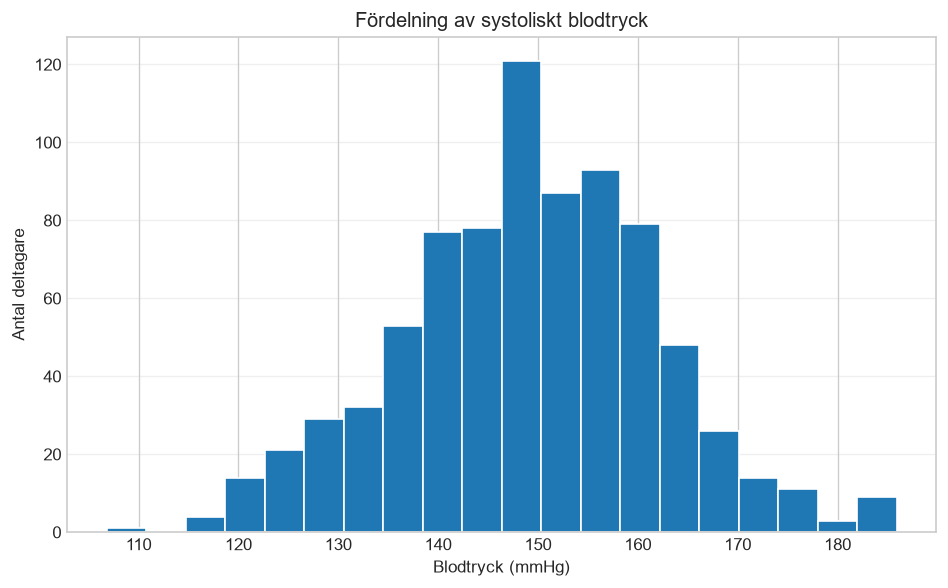

In [61]:
# Histogram för blodtryck
fig, ax = plt.subplots()

visualizer.hist(ax,"systolic_bp",
    "Fördelning av systoliskt blodtryck",
    "Blodtryck (mmHg)",
    "Antal deltagare"
)

fig.tight_layout()
plt.show()

**Tolkning:** Fördelningen liknar en normalfördelning. Den är klockformad och relativt symmetrisk. Men med en marginellt längre svans åt vänster, vilket kan tyda på en mycket svag vänsterskevhet. De flesta av observationerna ligger runt 150 mmHg i blodtryck.

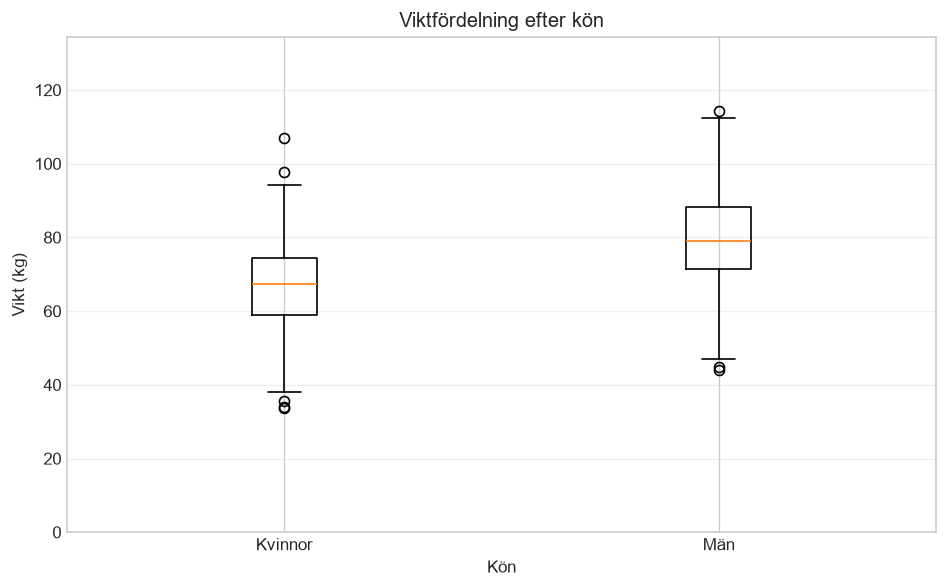

In [62]:
# Boxplot över vikt efter kön
visualizer.plot_weight_by_gender()

**Tolkning:** Viktfördelningen skiljer sig mellan män och kvinnor. Män har en högre medianvikt och större IQR, vilket betyder att vikten varierar mer bland män än bland kvinnor. Boxarna överlappar lite, men det finns ändå en tydlig skillnad mellan grupperna. Det finns ett extremvärde för högre vikt bland män och två bland kvinnor. För lägre vikter finns två extremvärden i båda grupperna. Medianen ligger längre ner i boxen för män och mer i mitten för kvinnor. Whiskers har ungefär samma längd ovanför som nedanför boxarna i båda grupperna. Det skulle kunna tyda på att viktfördelningen är ganska är symmetrisk.

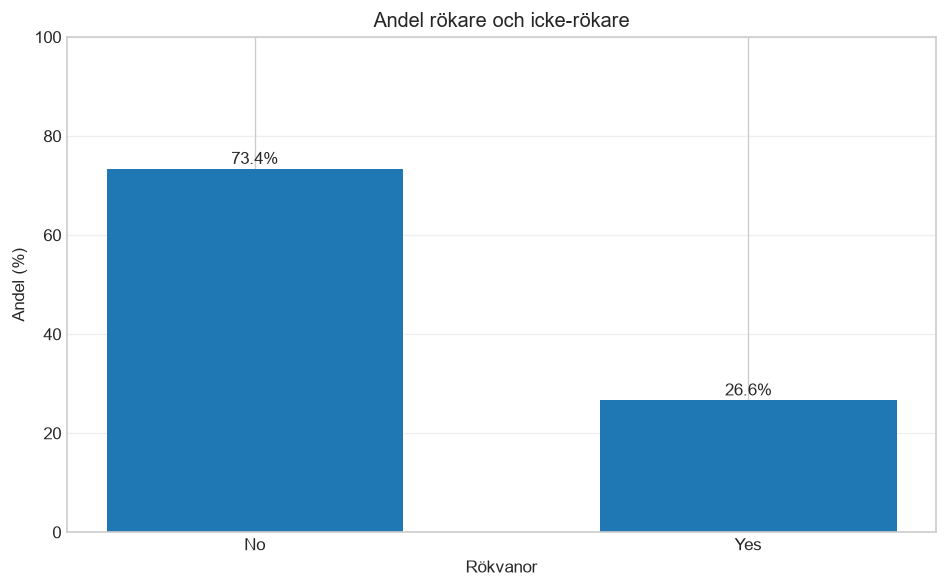

,antal,andel (%)
smoker,,
No,587,73.375
Yes,213,26.625


In [63]:
# Smoker summary
smoker_summary = analyzer.get_summary_smoker()
# Stapeldiagram över andelen rökare
# visualizer.plot_smoker(smoker_summary)
fig, ax = plt.subplots()
visualizer.barplot(
    ax,
    smoker_summary["andel (%)"].index,
    smoker_summary["andel (%)"].values,
    "Andel rökare och icke-rökare",
    "Rökvanor",
    "Andel (%)",
    ylim=(0, 100),
    labels=True
)
fig.tight_layout()
plt.show()
display(smoker_summary)

**Tolkning:** Stapeldiagrammet visar fördelningen mellan rökare och icke-rökare i studien. 73,4% röker och 26,6% röker inte av de 800 som undersökts. Grupperna rökare och icke-rökare har alltså olika storlek.

## Simulering

Simuleringen undersöker hur mycket andelen personer med en sjukdom kan variera vid ett slumpmässigt urval av 1 000 personer. Binomialfördelningen används eftersom utfallet är binärt: en person är antingen sjuk eller inte (1 eller 0). Genom att sätta ett slumpmässigt seed blir simuleringen repeterbar och kan återskapas.

In [64]:
show_results("Simulering av sjukandel", analyzer.simulate_disease_proportion())

---------------------------------------------
           Simulering av sjukandel           
---------------------------------------------
Verklig andel       : 0.059
Simulerad andel     : 0.056
Verklig andel (%)   : 5.9
Simulerad andel (%) : 5.6
---------------------------------------------


**Tolkning:** Den verkliga sjukandelen är 5,9% och simulerad 5,6%. Dvs om vi har 1000 personer så är 59 av dem sjuka jämfört med 56 personer i simuleringen. Den simulerade sjukandelen ligger alltså nära den verkliga andelen i studien. Det observerade resultatet varierar mellan olika urval på grund av slumpmässig variation. Resultaten kan skilja sig åt även om sannolikheten för sjukdom är samma för varje person. Ju fler som ingår desto mindre slumpvariation och desto stabilare uppskattning. 

Begränsningar
- Simuleringen antar att varje person har samma sannolikhet att ha sjukdomen och att observationerna är oberoende av varandra. Det är en förenkling, i verkligheten sjukdom i verkligheten kan påverkas av andra orsaker, som ålder, kön och livsstil.
- Simulering bygger på det befintliga datasetets sjukandel. Om det dataset inte är representativt för populationen kan simuleringen bli missvisande.

## Konfidensintervall för blodtryckets medelvärde

#### Ett 95% konfidensintervall för medelvärdet med normalapproximation
Normalapproximationen är en enkel och relativt snabb metod som bygger på centrala gränsvärdessatsen (Practical Statistics for Data Scientists, 2020). Den innebär att en normalfördelning kan användas som approximation när stickprovet är tillräckligt stort och observationerna är tillräckligt oberoende. I studien ingår 800 personer. Därför fungerar metoden bra här. Den gör det möjligt att beräkna ett konfidensintervall för populationens medelvärde från stickprovets medelvärde och standardavvikelse. Konfidensintervallet beräknas med ett kritiskt z-värde på 1,96, vilket motsvarar en konfidensnivå på 95%.

In [65]:
ci_normal_results = analyzer.calc_ci_normal("systolic_bp")

show_results("95% KI (normal)", ci_normal_results)

---------------------------------------------
               95% KI (normal)               
---------------------------------------------
n                    : 800
sd                   : 12.793
Medelvärde           : 149.179
Standardfel          : 0.452
Nedre konfidensgräns : 148.292
Övre konfidensgräns  : 150.065
---------------------------------------------


**Tolkning:** Medelvärdet är 149,18 mmHg och det 95-procentiga konfidensintervallet ligger mellan 148,29 och 150,07 mmHg. Det innebär att det uppskattade genomsnittliga systoliska blodtrycket i populationen ligger inom intervallet med en konfidensnivå på 95 %. Det är ganska smalt och det tyder på att uppskattningen är relativt säker.

Begränsningar
- Normalapproximationen bygger på att stickprovet är tillräckligt stort och att observationerna är tillräckligt oberoende. 

- Metoden kan fungera sämre vid små stickprov eller om vi har många extrema värden. 
Om saknade värden har tagits bort, så kan det också påverka om bortfallet inte är slumpmässigt. Eftersom vi har ett stickprov på 800 personer så är normalapproximationen ganska robust. Men det kan hända att studiens 800 observationer inte är representativa för hela populationen.

- Populationens standardavvikelse är inte tillgänglig och får skattas från stickprovet. Det ger en viss osäkerhet i resultatet.

#### Ett 95% konfidensintervall för medelvärdet med bootstrap

Bootstrap väljs för att jämföra konfidensintervallen och få en bättre bild av osäkerheten. Metoden används för att skatta osäkerheten utan att behöva anta att datan är normalfördelad. Den innebär att ett antal nya stickprov skapas genom att slumpmässigt dra observationer från originaldatasetet med återläggning. För varje nytt stickprov beräknas ett medelvärde. Genom att upprepa processen 10 000 gånger kan man undersöka hur mycket medelvärdet varierar och på så sätt uppskatta osäkerheten.

In [66]:
ci_boot_results = analyzer.calc_ci_bootstrap(column="systolic_bp", n_boot = 10_000)

show_results("95% KI (bootstrap)", ci_boot_results)

---------------------------------------------
              95% KI (bootstrap)             
---------------------------------------------
Medelvärde           : 149.179
Nedre konfidensgräns : 148.307
Övre konfidensgräns  : 150.074
---------------------------------------------


**Tolkning:** Det beräknade 95-procentiga konfidensintervallet ligger mellan 148,31 och 150,07 mmHg. Det visar inom vilket intervall det sanna genomsnittliga blodtrycket i populationen förväntas ligga. Eftersom intervallet är ganska smalt tyder det på att uppskattningen är relativt säker. 

Begränsningar

- Bootstrap bygger på att urvalet är representativt. Om urvalet är för litet eller inte speglar populationen blir också konfidensintervallet missvisande.
- Bootstrapmetoden visar hur mycket medelvärdet kan variera beroende på vilka värden som finns med i stickprovet. Metoden kan alltså uppskatta slumpmässig osäkerhet, men inte korrigera exempelvis urvalsfel eller fel i datainsamlingen.

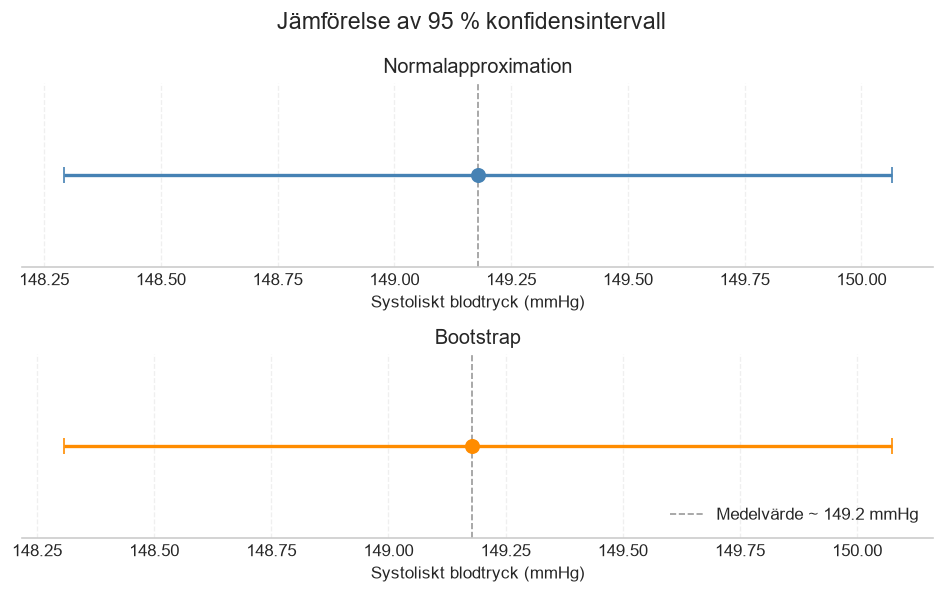

In [67]:
n = ci_normal_results["n"]
std_bp = ci_normal_results["sd"]
mean_bp = ci_normal_results["Medelvärde"]
standard_error = ci_normal_results["Standardfel"]

lower_normal = ci_normal_results["Nedre konfidensgräns"]
upper_normal = ci_normal_results["Övre konfidensgräns"]

lower_boot = ci_boot_results["Nedre konfidensgräns"]
upper_boot = ci_boot_results["Övre konfidensgräns"]

fig, ax = plt.subplots(2, 1, sharex=False)

# Normalapproximation
visualizer.errorbarplot(
    ax[0], mean_bp, lower_normal, upper_normal,
    "Normalapproximation",
    "Systoliskt blodtryck (mmHg)",
    "steelblue"
)

# Bootstrap
visualizer.errorbarplot(
    ax[1], mean_bp, lower_boot, upper_boot,
    "Bootstrap",
    "Systoliskt blodtryck (mmHg)",
    "darkorange"
)

fig.suptitle("Jämförelse av 95 % konfidensintervall", fontsize=14)

# Tar bort onödiga ramar
for a in ax:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_visible(False)

ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [68]:
show_results(
    "Systoliskt blodtryck",
    {
        "Antal observationer (n)": n,
        "Medelvärde (mmHg)": mean_bp,
        "Standardavvikelse (SD)": std_bp,
        "Standardfel (SE)": standard_error,

        "95% konfidensintervall": None,
        "Normalapproximation, nedre gräns": lower_normal,
        "Normalapproximation, övre gräns": upper_normal,
        "Bootstrap, nedre gräns": lower_boot,
        "Bootstrap, övre gräns": upper_boot
    }
)

---------------------------------------------
             Systoliskt blodtryck            
---------------------------------------------
Antal observationer (n)          : 800
Medelvärde (mmHg)                : 149.179
Standardavvikelse (SD)           : 12.793
Standardfel (SE)                 : 0.452

95% konfidensintervall
---------------------------------------------
Normalapproximation, nedre gräns : 148.292
Normalapproximation, övre gräns  : 150.065
Bootstrap, nedre gräns           : 148.307
Bootstrap, övre gräns            : 150.074
---------------------------------------------


**Jämförelse av de två 95-procentiga konfidensintervallen för systoliskt blodtryck**

- Normalapproximations-metoden använder medelvärdet och standardfelet för att uppskatta ett intervall där populationens sanna medelvärde förväntas ligga. Metoden bygger på att stickprovsmedelvärdet är ungefär normalfördelat och det är ofta rimligt vid tillräckligt stora stickprov.

- Bootstrap: Metoden skapar 10 000 nya stickprov genom slumpmässig dragning med återläggning från originaldatan. Medelvärdet beräknas för varje stickprov och de 2,5 och 97,5 percentilerna används som konfidensintervallets gränser.

- De två intervallens nedre och övre gränser är väldigt lika och tyder det på att metoderna ger ungefär samma uppskattning av osäkerheten. Intervallet är ganska smalt och det kan tyda på att skattningen är nära populationens medelvärde. Eftersom bägge ger ett liknande resultat så kan det bero på att datasetet är tillräckligt stort och observationerna är oberoende. Om resultatet hade varit olika hade det kunnat bero på fördelningen eller stickprovets egenskaper.

## Hypotesprövning ”Rökare har högre medel-blodtryck än icke-rökare”
Welch's t-test (ensidigt) har valts eftersom testet jämför medelvärdet mellan två oberoende grupper och fungerar också när grupperna har olika variation och antal. Det kräver inte lika varians. Welch's t-test förutsätter att observationerna är oberoende och att blodtrycket är någorlunda normalfördelat inom grupperna och att urvalen är tillräckligt stora för att testet ska vara robust. Här jämförs 213 rökare med 587 icke-rökare. Det är ensidigt eftersom vi vill undersöka om rökare har ett **högre** genomsnittligt blodtryck än icke-rökare. Signifikansnivån sätts till 5% (α = 0,05).

Testet utgår från hypoteserna:
- Nollhypotes (H₀): Rökare har inte ett högre medel-blodtryck än icke-rökare.
- Alternativhypotes (H₁): Rökare har ett högre medel-blodtryck än icke-rökare.
    - H₀: μR ≤ μIR
    - H₁: μR > μIR 


In [69]:
# Welchs t-test

s_results = analyzer.get_smoker_data()
smokers_results = s_results["smokers"]
non_smokers_results = s_results["non_smokers"]
diff_means = s_results["mean_difference"]

# Ensidigt t-test och variansen antas inte behöva vara lika
t_stat, p_value = stats.ttest_ind(
    smokers_results["data"],
    non_smokers_results["data"],
    equal_var=False,
    alternative="greater"
)

show_results(
    "Welch's t-test",
    {
        "Antal rökare": smokers_results["n"],
        "Antal icke-rökare": non_smokers_results["n"],
        "Medelvärde rökare": smokers_results["mean"],
        "Medelvärde icke-rökare": non_smokers_results["mean"],
        "Skillnad i medelvärde": diff_means,
        "t-statistika": t_stat,
        "p-värde": p_value
    }
)

if p_value < 0.05:
    print("Resultat: Vi förkastar nollhypotesen.")
    print("Det finns statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare")
else:
    print("Resultat: Vi kan inte förkasta nollhypotesen.")
    print("Det finns inte tillräckligt statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare")

---------------------------------------------
                Welch's t-test               
---------------------------------------------
Antal rökare           : 213
Antal icke-rökare      : 587
Medelvärde rökare      : 149.525
Medelvärde icke-rökare : 149.053
Skillnad i medelvärde  : 0.472
t-statistika           : 0.450
p-värde                : 0.326
---------------------------------------------
Resultat: Vi kan inte förkasta nollhypotesen.
Det finns inte tillräckligt statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare


**Tolkning:** 
Welch's t-test (ensidigt) ger en t-statistik på 0,450 och ett p-värde på 0,326. Eftersom p-värdet är större än signifikansnivån 0,05 kan vi inte förkasta nollhypotesen. Resultatet ger alltså inte statistiskt signifikant stöd för att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare. Det genomsnittliga systoliska blodtrycket var 149,53 mmHg hos rökare och 149,05 mmHg hos icke-rökare. Skillnaden mellan gruppernas medelvärden är cirka 0,47 mmHg. Även om rökarnas medelvärde är något högre är skillnaden liten och kan bero på slumpmässig variation. Det innebär inte att skillnaden saknas, utan att det inte finns tillräckligt statistiskt stöd för att dra slutsatsen att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.

Begränsningar
- Welch t-test bygger på att grupperna ska vara oberoende av varandra och observationerna inom varje grupp ska vara oberoende. 
Blodtrycket antas vara ungefärligt normalfördelat inom grupperna, särskilt vid mindre urval.
- Testet undersöker skillnaden i medelvärden och tar inte hänsyn till andra faktorer som kan påverka blodtrycket, exempelvis ålder och livsstil.

## Gör en simulering för att undersöka hur säkert ditt hypotes­test är

Welchs t-test används för att jämföra rökare och icke-rökare och undersöka hur stora skillnader som krävs för att kunna upptäckas. Eftersom det är två oberoende grupper som jämförs så används ett ensidigt Welchs t-test även i simuleringarna. Simuleringarna används för att undersöka hur möjligheten att upptäcka en skillnad förändras beroende på hur skillnadens storlek mellan grupperna. För att undersöka testets styrka (power) görs 2 000 simuleringar för varje effektstorlek. Den första skillnaden är 0,47 mmHg motsvarar den ungefärliga skillnaden mellan grupperna i orginaldatat. Sedan ökas skillnaden mellan rökare och icke-rökare på för att undersöka hur det påverkar testets förmåga att upptäcka dem. De skillnader som testas är 0,47, 1, 2, 3 och 5 mmHg. En vanlig riktlinje är att testets power bör vara minst 80 %.

I varje simulering skapas två grupper med lika många personer och ungefär samma spridning i blodtrycket som i originaldatat. Därefter testas om rökarnas blodtryck är högre än icke-rökarnas, med en signifikansnivå på 0,05. 

**Power** beräknas genom att undersöka hur stor andel av simuleringarna som ger ett statistiskt signifikant resultat (p < 0,05). Power ger sannolikheten att testet upptäcker en skillnad i blodtryck mellan rökare och icke-rökare när en sådan finns. 

In [70]:
# Vad händer med power när skillnaden mellan grupperna ökar?
# Hur svårt är det att upptäcka skillnaderna mellan rökare och icke-rökare
n_sim = 2000
alpha = 0.05
effect_sizes = [0.47, 1, 2, 3, 5]

simulated_power = analyzer.run_power_analysis(
    effect_sizes, n_sim, alpha)

show_results("Effektmått och spridningsmått",
             {
                 "Standardavvikelse rökare": smokers_results["std"],
                 "Standardavvikelse icke-rökare": non_smokers_results["std"],
                 "Cohens d": analyzer.calculate_cohens_d()
             }
             )

display_summary = simulated_power.copy()
display_summary["power"] = (display_summary["power"] * 100).round(2)
display_summary = display_summary.rename(columns={"power": "power (%)"})

display(display_summary)

---------------------------------------------
        Effektmått och spridningsmått        
---------------------------------------------
Standardavvikelse rökare      : 13.268
Standardavvikelse icke-rökare : 12.626
Cohens d                      : 0.037
---------------------------------------------


,effekt,antal_signifikanta,power (%)
0,0.47,239,11.95
1,1.00,469,23.45
2,2.00,1149,57.45
3,3.00,1781,89.05
4,5.00,1997,99.85


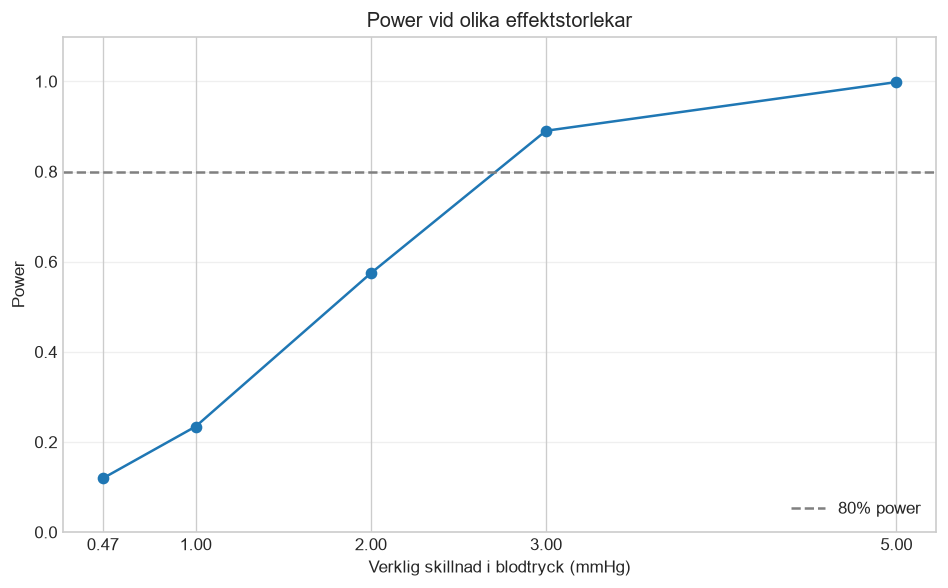

In [71]:
visualizer.plot_power(simulated_power)

**Tolkning:** Diagrammet visar att power ökar med effektstorlek. Vid små skillnader på 0,47 och 1 mmHg är sannolikheten att upptäcka en signifikant skillnad låg. Vid 2 mmHg ökar power till 57%, vid 3 mmHg är den 89%, medan en stor skillnad på 5 mmHg nästan alltid hittas. Det kan betyda att testet lättare upptäckar stora skillnader, men är sämre på att hitta små skillnader i blodtryck. Vid den minsta simulerade effektstorleken 0,47 mmHg är power 11,95%. Det kan vara en förklaring till att den ursprungliga hypotesprövningen inte blev statistiskt signifikant (p=0,326). 

Skillnaden mellan grupperna är 0,47 mmHg. Det kan innebära att skillnaden är svår att upptäcka om variansen är relativt hög. Standardavvikelsen är 13,27 för rökare och 12,63 för icke-rökare. Värdena varierar alltså ungefär lika mycket i båda grupperna. Enligt Cohens d motsvarar skillnaden mellan rökare och icke-rökare bara 0,04 standardavvikelser.

Begränsningar
- Power påverkas bland annat av effektstorlek, stickprovsstorlek, variation i data och signifikansnivå. 
- Små skillnader kräver ofta fler deltagare för att få tillräckligt hög power
- En hög power innebär mindre risk för typ II-fel, det vill säga att missa en verklig skillnad. 
- Effekstorlekarna som valts kanske inte motsvarar de skillnader som finns i populationen.

## Multipel regression

En multipel linjär regression görs för att undersöka om fler variabler tillsammans kan skatta blodtrycket. Det visar vilka variabler som skulle kunna påverka blodtrycket. Analysen fokuserar på numeriska variabler eftersom de kan användas direkt i regressionsmodellen. De kategoriska variablerna behöver först göras om till numeriska värden. (Practical Statistics for Data Scientists, 2020.)

#### Korrelationstest
Korrelationstest görs för att undersöka om det finns samband mellan de olika numeriska variablerna och blodtrycket. Det visar också om variablerna har starka samband med varandra.
- Korrelation nära +1 = starkt positivt samband.
- Korrelation nära -1 = starkt negativt samband.
- Korrelation nära 0 = svagt linjärt samband.

In [72]:
# Undersöker hur de numeriska variablerna samvarierar.

features_corr = [
    "age", "height", "weight",
    "systolic_bp", "cholesterol", "disease"
]

numeric_df = df[features_corr]
correlation = numeric_df.corr()

# Sorterar sambanden med systoliskt blodtryck.
# För att undersöka vilka variabler som har
# starkast linjärt samband med blodtrycket.
correlation_results = (
    correlation["systolic_bp"]
    .sort_values(ascending=False)
    .round(3)
    .to_dict()
)

show_results(
    "Korrelation med systoliskt blodtryck",
    correlation_results
)

---------------------------------------------
     Korrelation med systoliskt blodtryck    
---------------------------------------------
systolic_bp : 1.000
age         : 0.608
cholesterol : 0.368
weight      : 0.179
height      : 0.086
disease     : 0.031
---------------------------------------------


**Tolkning:** Korrelationen visar att ålder har det starkaste positiva sambandet med systoliskt blodtryck, med en korrelationskoefficient på 0,608. Det kan tyda på att systoliskt blodtryck ökar med ålder. Även kolesterol har ett positivt samband (0,368), medan vikt (0,179) och längd (0,086) bägge har svaga samband. Variabeln disease har ett mycket svagt samband, 0,031. Främst ålder och kolesterol och i viss mån vikt verkar vara relevanta variabler för att förklara variationen i systoliskt blodtryck. 

#### Multikollinearitet
Undersöker om det finns multikollinearitet mellan de oberoende variablerna i regressionsmodellen genom VIF-värden (Variance Inflation Factor). 

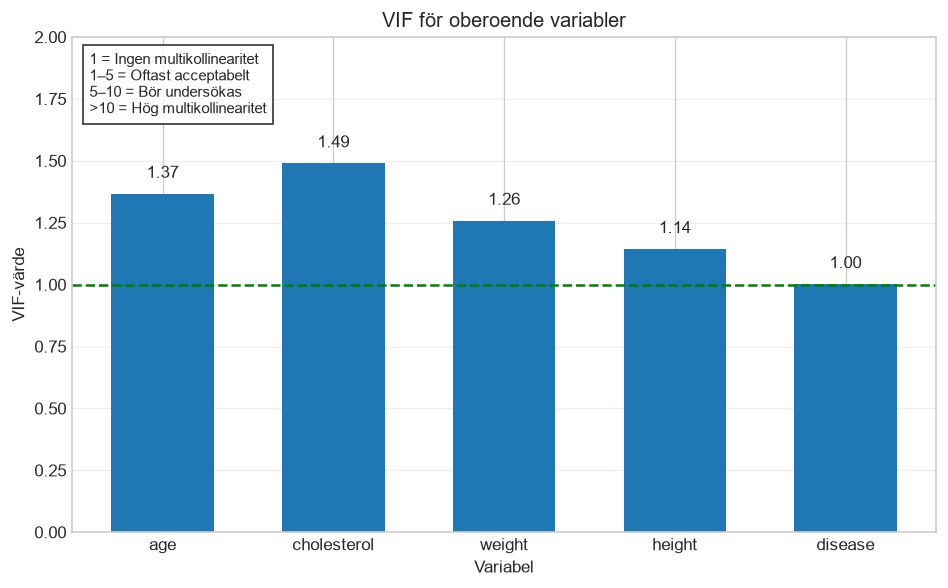

In [73]:
def calculate_vif(df_vif, features):
    """ 
    Calculates the Variance Inflation Factor (VIF) for each feature in the dataset.
    VIF is a measure of multicollinearity in a regression model.
    """
    X = df_vif[features]
    vif_values = []

    for co in X.columns:
        y = X[co]
        X_other = X.drop(columns=[co])

        model = LinearRegression()
        model.fit(X_other, y)

        r_squared = model.score(X_other, y)
        vif = 1 / (1 - r_squared)

        vif_values.append(vif)

    vif_data = pd.DataFrame({
        "Variabel": X.columns,
        "VIF": vif_values
    })

    return vif_data

features_vif = ["age", "cholesterol", "weight", "height", "disease"]

vif_results = calculate_vif(df, features_vif)

def plot_vif(ax, vif_data):
    """ Plots the Variance Inflation Factor (VIF) for each feature in a dataset """
    x = vif_data["Variabel"]
    y = vif_data["VIF"]

    visualizer.barplot(
        ax=ax,
        x=x,
        y=y,
        title="VIF för oberoende variabler",
        xlabel="Variabel",
        ylabel="VIF-värde",
        grid=True,
        ylim=(0, 2),
        labels=False
    )

    # Skriver ut VIF-värden ovanför staplarna
    bars = ax.patches

    for b in bars:
        height = b.get_height()
        ax.text(
            b.get_x() + b.get_width() / 2,
            height + 0.05,
            f"{height:.2f}",
            ha="center",
            va="bottom"
        )

    # Referenslinje vid VIF = 1
    ax.axhline(
        y=1,
        color="green",
        linestyle="--",
        label="VIF = 1"
    )

    # Förklarande text
    ax.text(
        0.02, 0.97,
        "1 = Ingen multikollinearitet\n"
        "1–5 = Oftast acceptabelt\n"
        "5–10 = Bör undersökas\n"
        ">10 = Hög multikollinearitet",
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.8)
    )

    return ax


fig, ax = plt.subplots()
plot_vif(ax, vif_results)
plt.tight_layout()
plt.show()

**Tolkning:** VIF-värdena är på 1,37 för ålder, 1,49 för kolesterol och 1,26 för vikt. Om värdet är 1 så är det ingen multikollinearitet, men överstiger det 5 så bör det undersökas närmre. Samtliga värden är nära 1 och det tyder på att det inte finns några problem med multikollinearitet mellan variablerna. De kan användas i den multipla linjära regressionsmodellen. 

### Multipel linjär regression
Undersöker om variablerna ålder, kolesterol och vikt tillsammans kan förutsäga blodtrycket.

In [84]:
y = df["systolic_bp"]

features = ["age", "cholesterol", "weight"]
X_multi = df[features]

# Om samma uppdelning används igen så bör modellerna
# jämföras på exakt samma testpersoner.
X_train_multi, X_test_multi, y_train_multi, y_test_multi = (
    train_test_split(
        X_multi, y, test_size=0.2, random_state=42
    )
)

model_multi = LinearRegression()
model_multi.fit(X_train_multi, y_train_multi)

pred_multi = model_multi.predict(X_test_multi)

r2_multi = r2_score(y_test_multi, pred_multi)
# Varför sqrt av mean squared error
mse_multi = mean_squared_error(y_test_multi, pred_multi)
mae_multi = mean_absolute_error(y_test_multi, pred_multi)
rmse_multi = np.sqrt(
    mse_multi
)

result_multi = {
    "Intercept": f"{model_multi.intercept_:.3f}",
    **{
        feature: f"{coefficient:.4f}"
        for feature, coefficient in zip(
            features, model_multi.coef_
        )
    },
    "R²": f"{r2_multi:.3f}",
    "MAE": f"{mae_multi:.2f} mmHg",
    "MSE": f"{mse_multi:.2f} mmHg²",
    "RMSE": f"{rmse_multi:.2f} mmHg"
}
show_results(
    "Multipel linjär regression",
    result_multi
)


---------------------------------------------
          Multipel linjär regression         
---------------------------------------------
Intercept   : 108.208
age         : 0.5090
cholesterol : 0.6559
weight      : 0.1692
R²          : 0.422
MAE         : 7.64 mmHg
MSE         : 95.07 mmHg²
RMSE        : 9.75 mmHg
---------------------------------------------


#### Jämför faktiska och skattade blodtryck 
Undersöker hur nära modellens skattningar ligger de verkliga blodtrycksvärdena. Ju närmare punkterna ligger den diagonala linjen, desto bättre överensstämmelse.

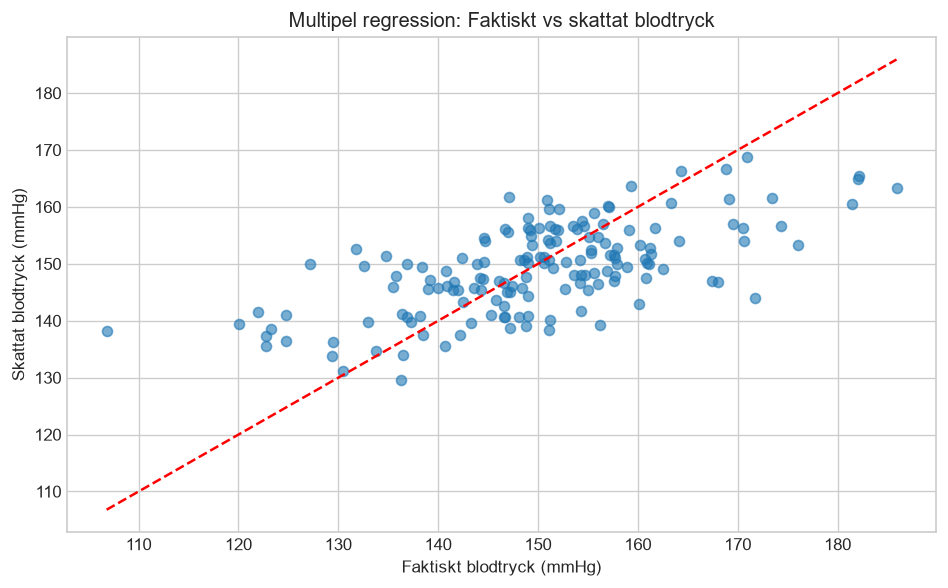

In [85]:
plt.figure()

plt.scatter(y_test_multi, pred_multi, alpha=0.6)

# Referenslinje där skattat värde = faktiskt värde
min_value = min(y_test_multi.min(), pred_multi.min())
max_value = max(y_test_multi.max(), pred_multi.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--"
)

plt.xlabel("Faktiskt blodtryck (mmHg)")
plt.ylabel("Skattat blodtryck (mmHg)")
plt.title("Multipel regression: Faktiskt vs skattat blodtryck")
plt.tight_layout()
plt.show()

**Tolkning:** En multipel linjär regressionsanalys används för att undersöka hur ålder, kolesterolnivå och vikt kan skatta systoliskt blodtryck. Alla tre variabler har ett positivt samband med det skattade blodtrycket, när övriga variabler är konstanta. Ålder har den största koefficienten. En ökning med ett år gör att det skattade blodtrycket ökar med cirka 0,51 mmHg.

R²-värdet: Modellen kan förklarar 42,2 % av variationen i blodtrycket i testdatan. Resten 57,8 % förklaras inte av variablerna i modellen. Hur stora är modellens prediktionsfel? Det genomsnittliga absoluta prediktionsfelet (MAE) är 7,64 mmHg. Modellens RMSE är 9,75 mmHg. Det innebär att skattningarna överlag avviker med 9,75 mmHg från de faktiska värdena. Att RMSE är högre än MAE kan tyda på att modellen ibland gör ganska stora fel.

Modellens ekvation blir:

$\widehat{BP}$ = 108,208 + 0,509Age + 0,6559Cholesterol + 0,1692Weight

- Intercept (108,208): Modellens startvärde när alla förklarande variabler är noll.

- Age (0,5090): Blodtrycket ökar med cirka 0,51 mmHg för varje år, om övriga variabler är konstanta.

- Cholesterol (0,6559): Blodtrycket ökar med cirka 0,66 mmHg för varje enhets ökning av kolesterol, om övriga variabler är konstanta.

- Weight (0,1692): Blodtrycket ökar med cirka 0,17 mmHg för varje extra kilo, om övriga variabler är konstanta.

#### Har modellen en tendens att över- eller underskatta? Hur mycket varierar felen? 
Residualen är skillnaden mellan det faktiska och det förutsagda värdet för varje observation. Modellens fel undersöks genom att jämföra faktiska och förutsagda blodtrycksvärden. 

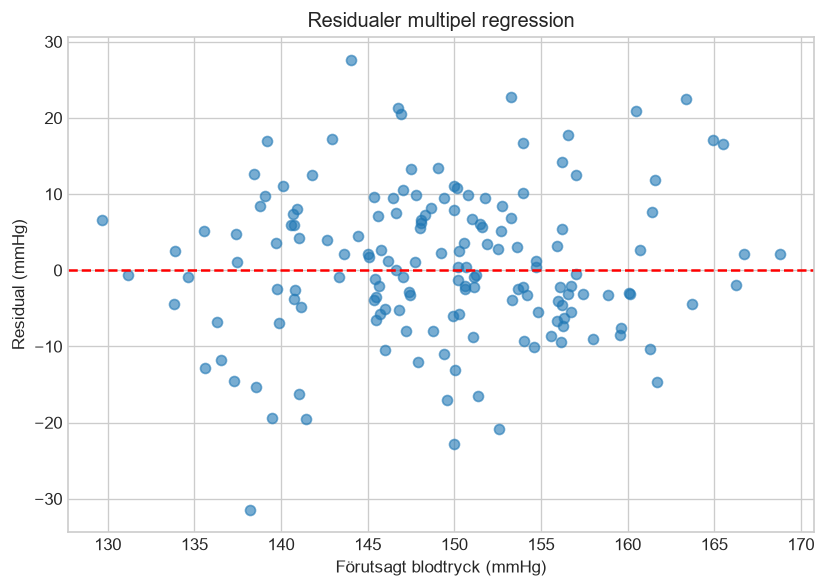

In [86]:
residuals = y_test_multi - pred_multi

plt.figure(figsize=(7, 5))
plt.scatter(pred_multi, residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Förutsagt blodtryck (mmHg)")
plt.ylabel("Residual (mmHg)")
plt.title("Residualer multipel regression")
plt.tight_layout()
plt.show()

In [87]:
residual_results = {
    "Medelvärde residualer": f"{residuals.mean():.3f}",
    "Standardavvikelse residualer": f"{residuals.std():.3f}",
    "Största residual": f"{residuals.max():.3f}",
    "Minsta residual": f"{residuals.min():.3f}"
}

show_results("Residualer", residual_results)

---------------------------------------------
                  Residualer                 
---------------------------------------------
Medelvärde residualer        : 0.760
Standardavvikelse residualer : 9.751
Största residual             : 27.672
Minsta residual              : -31.428
---------------------------------------------


**Tolkning:** Residualernas medelvärde är cirka 0,76, ganska nära noll. Det tyder på att modellen inte har någon större genomsnittlig systematisk över- eller underskattning. Men enligt residualernas spridning och största avvikelser så får modellen ibland relativt stora fel. Modellen kan ibland underskatta blodtrycket med 27,67 mmHg och överskatta med 31,43 mmHg.


Residualerna är relativt slumpmässigt fördelade runt noll-linjen. Det tyder på att modellen inte har några tydliga systematiska fel och verkar fånga sambanden i datan. Det finns några punkter som ligger långt ifrån men inga uppenbara mönster som skulle kunna betyda att modellen missar viktiga samband.

Begränsningar

- Det ska finnas ett någorlunda linjärt samband mellan de variabler vi använder och det vi vill skatta.
- Residualerna ska vara ungefärligt normalfördelade.
- Homoskedasticitet: Residualerna ska ha ungefär konstant varians oavsett vilket värde modellen skattar.
- Multikollinearitet: Variablerna ska inte vara alltför starkt korrelerade med varandra.
- Observationerna och residualerna ska vara oberoende av varandra.
- Enskilda observationer ska inte påverka modellen för mycket.

## PCA - huvudkomponentsanalys
PCA används för att få en bättre överblick över mönster och samband mellan flera numeriska variabler. Metoden omvandlar variablerna till huvudkomponenter som sammanfattar informationen i datan. Då variablerna har olika skalor och enheter behöver de standardiseras innan analysen. PCA kompletterar regressionsanalysen genom att visa övergripande mönster i datan. (Practical Statistics for Data Scientists, 2020)

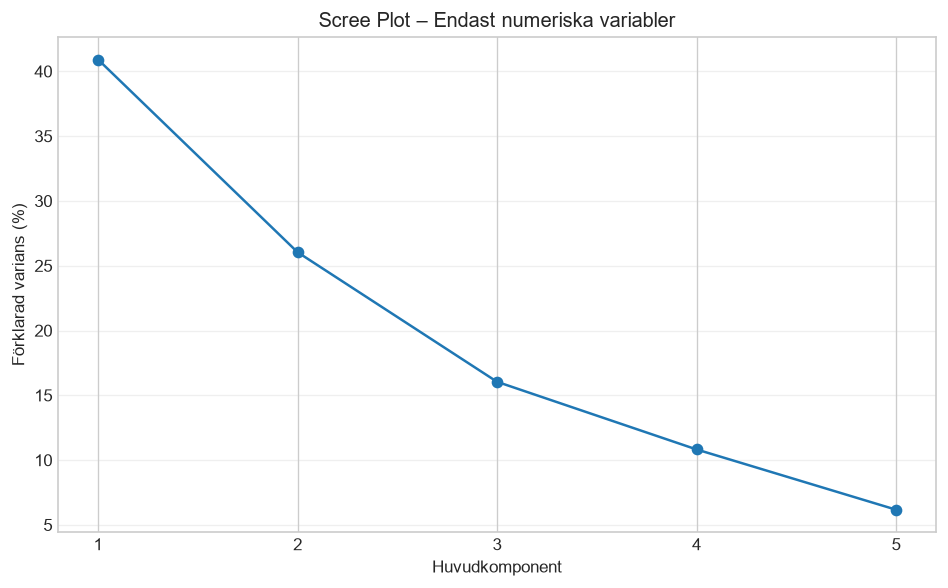

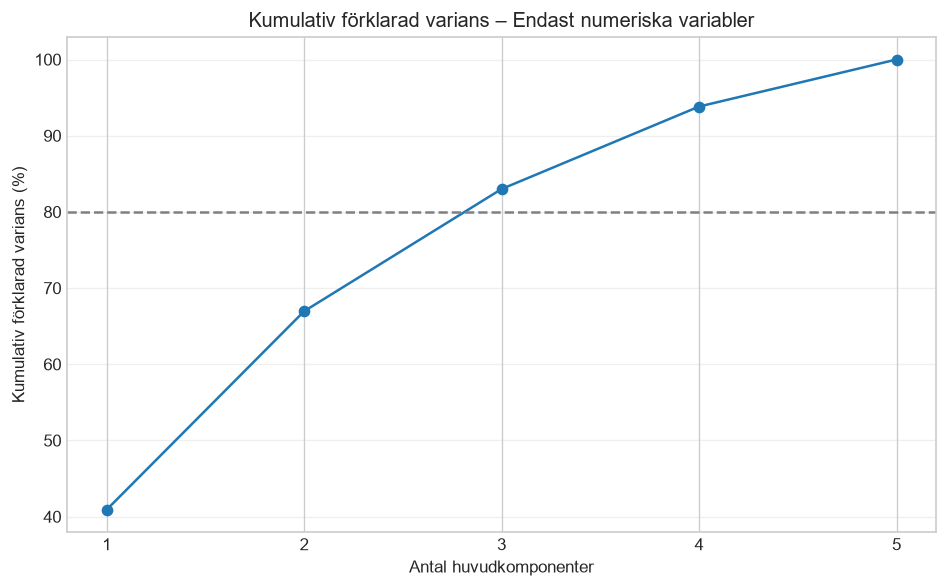

In [88]:
def calc_pca(df_c, feat):
    """
    Implements PCA analysis on a dataframe
    """
    # Standardiserar variablerna.
    # Genomför PCA och skriver ut förklarad varians.
    # Välj variabler

    X = df_c[feat].dropna()       # Tar bort observationer med saknade värden

    # Standardisera variablerna
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Utför PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    return pca, X_pca, X.index

# Scree Plot and Cumulative Explained Variance
def plot_variance(pca, titel):
    """
    Plots the explained variance and cumulative explained variance.
    """

    explained_var = pca.explained_variance_ratio_ * 100
    cumulative_variance = np.cumsum(explained_var)

    components = range(1, len(explained_var) + 1)

    # Skapar två diagram under varandra

    # Diagram 1: Scree Plot
    fig, ax = plt.subplots()

    visualizer.lineplot(
        ax=ax,
        x=components,
        y=explained_var,
        title=f"Scree Plot – {titel}",
        xlabel="Huvudkomponent",
        ylabel="Förklarad varians (%)",
        grid=True,
        xticks=components
    )
    plt.tight_layout()
    plt.show()
    # Diagram 2: Kumulativ förklarad varians
    fig, ax = plt.subplots()

    visualizer.lineplot(
        ax=ax,
        x=components,
        y=cumulative_variance,
        title=f"Kumulativ förklarad varians – {titel}",
        xlabel="Antal huvudkomponenter",
        ylabel="Kumulativ förklarad varians (%)",
        grid=True,
        xticks=components
    )

    # Referenslinje vid 80 %
    ax.axhline(
        y=80,
        color="gray",
        linestyle="--",
        label="80 %"
    )

    plt.tight_layout()
    plt.show()


# Skapar en kopia av originaldatasetet
df_pca = df.copy()

# Mappa kön till numeriska värden
df_pca["sex"] = df_pca["sex"].map({
    "M": 0,
    "F": 1
})

# Mappa rökvanor till numeriska värden
df_pca["smoker"] = df_pca["smoker"].map({
    "No": 0,
    "Yes": 1
})
features_numeric = [
    "age", "cholesterol", "weight",
    "height", "systolic_bp"
]

pca_numeric, X_pca_numeric, index_numeric = calc_pca(
    df_pca, features_numeric
)
plot_variance(
    pca_numeric,
    "Endast numeriska variabler"
)


In [89]:
# Skriv ut förklarad varians
variance_results = {
    f"PC{i+1}": f"{variance * 100:.1f}%"
    for i, variance in enumerate(
        pca_numeric.explained_variance_ratio_
    )
}

show_results("Förklarad varians", variance_results)
# print("\nNumeriska variabler:")
# print(f"PC1 + PC2 förklarar {pca_numeric.explained_variance_ratio_[:2].sum() * 100:.1f}% av den totala variansen.")
# print(f"PC1 + PC2 + PC3 förklarar {pca_numeric.explained_variance_ratio_[:3].sum() * 100:.1f}% av den totala variansen.")

---------------------------------------------
              Förklarad varians              
---------------------------------------------
PC1 : 40.9%
PC2 : 26.0%
PC3 : 16.0%
PC4 : 10.8%
PC5 : 6.2%
---------------------------------------------


**Tolkning:** Diagrammen över förklarad och kumulativt förklarad varians (PCA). De används för att se hur mycket variation varje huvudkomponent (PC1, PC2, PC3 osv.) förklarar i datan. Resultaten visade att den första huvudkomponenten (PC1) förklarade 40,9 % av variationen och den andra (PC2) förklarade 26,0 %. Tillsammans förklarade de 66,9 % av den totala variationen i datan. 

Scree Plot har en tydlig böj vid den tredje huvudkomponenten (PC3). De tre första huvudkomponenterna verkar beskriva en stor del av variationen i datasetet. PC1, PC2 och PC3 förklarar tillsammans 83,0% av variationen. Därför kan de vara lämpliga att undersöka för att hitta mönster i datan.

In [90]:
# Undersöker vilka ursprungliga variabler som bidrar
# mest till respektive huvudkomponent. Större absolutvärde innebär större bidrag.

def get_loadings(pca, features_load):
    """ 
    Displays PCA loadings for each feature and principal component
    """
    loadings = pd.DataFrame(
        pca.components_.T,
        columns=[f"PC{i+1}" for i in range(pca.n_components_)],
        index=features_load
    )
    return loadings



loadings_numeric = get_loadings(
    pca_numeric, features_numeric
)

print("\n----- PCA LOADINGS: Endast numeriska variabler -----")
print(loadings_numeric.round(3).to_string())


----- PCA LOADINGS: Endast numeriska variabler -----
               PC1    PC2    PC3    PC4    PC5
age          0.573 -0.280  0.277 -0.143  0.704
cholesterol  0.526 -0.069 -0.517 -0.563 -0.366
weight       0.247  0.657 -0.495  0.388  0.334
height       0.098  0.694  0.556 -0.433 -0.111
systolic_bp  0.569 -0.059  0.318  0.570 -0.496


**Tolkning:** Loadings visar hur starkt de olika variablerna bidrar till respektive huvudkomponent. PC1 påverkas främst av ålder, kolesterol och systoliskt blodtryck. PC2 påverkas framför allt av längd och vikt. PC3 påverkas främst av längd, kolesterol och vikt. Längd har en positiv laddning, medan kolesterol och vikt har negativa laddningar på PC3.

Det tyder på att datan innehåller olika mönster: ett kopplat till ålder, kolesterol och blodtryck samt ett kopplat till kroppsstorlek.

Först undersöks två huvudkomponenter (PC1 och PC2) för att se hur stor del av variationen de förklarar. Efter det undersöks om den tredje komponenten (PC3) tillför mer information om eventuella grupper i datamaterialet.

#### Visualisering med två huvudkomponenter

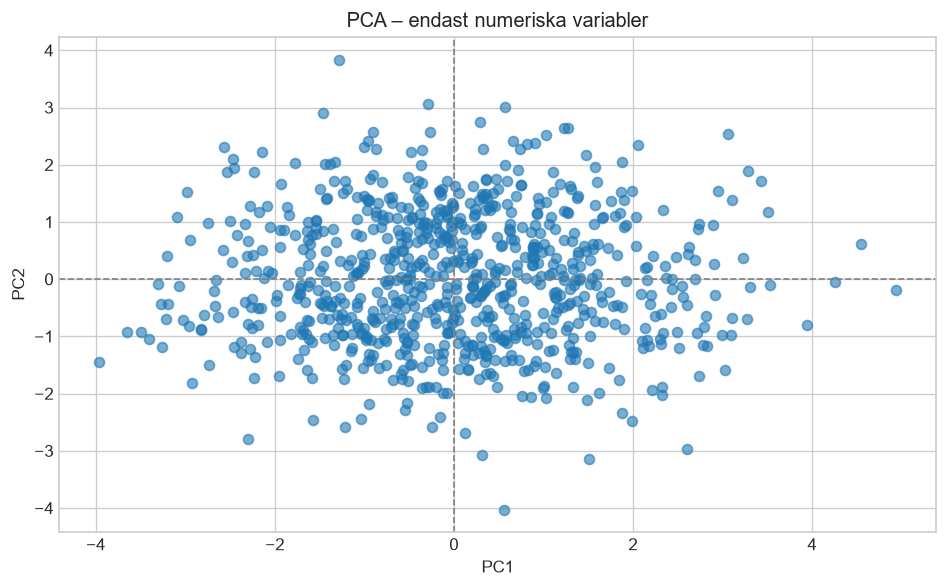

In [91]:
def plot_pca_2d(X_pca, titel):
    """ 
    Plots the PCA score plot for the first two principal components
    """
    # Rita PCA-diagram
    plt.figure()
    plt.axhline(y=0, color="gray", linestyle="--", linewidth=1)
    plt.axvline(x=0, color="gray", linestyle="--", linewidth=1)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6)

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(titel)
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
plot_pca_2d(
    X_pca_numeric,
    "PCA – endast numeriska variabler"
)

**Tolkning:**
De flesta observationerna ligger samlade nära mitten och att det inte finns någon tydlig gruppering. Några punkter ligger längre från mitten och skiljer sig från övriga observationer. Det finns alltså inga tydliga separata grupper utifrån de två första huvudkomponenterna. Det kan tyda på att observationerna inte bildar några tydliga grupper utifrån de numeriska variablerna.

Variablerna är standardiserade med StandardScaler. Det innebär att variablerna får samma skala och att variabler med större numeriska värden inte automatiskt får större påverkan på PCA-analysen. Utan standardisering skulle variabler med större numeriska värden kunna påverka analysen mer, exempelvis eftersom vikt mäts i kilo och blodtryck i mmHg.

#### Visualisering med två huvudkomponenter, färglagd efter sjukdomsstatus

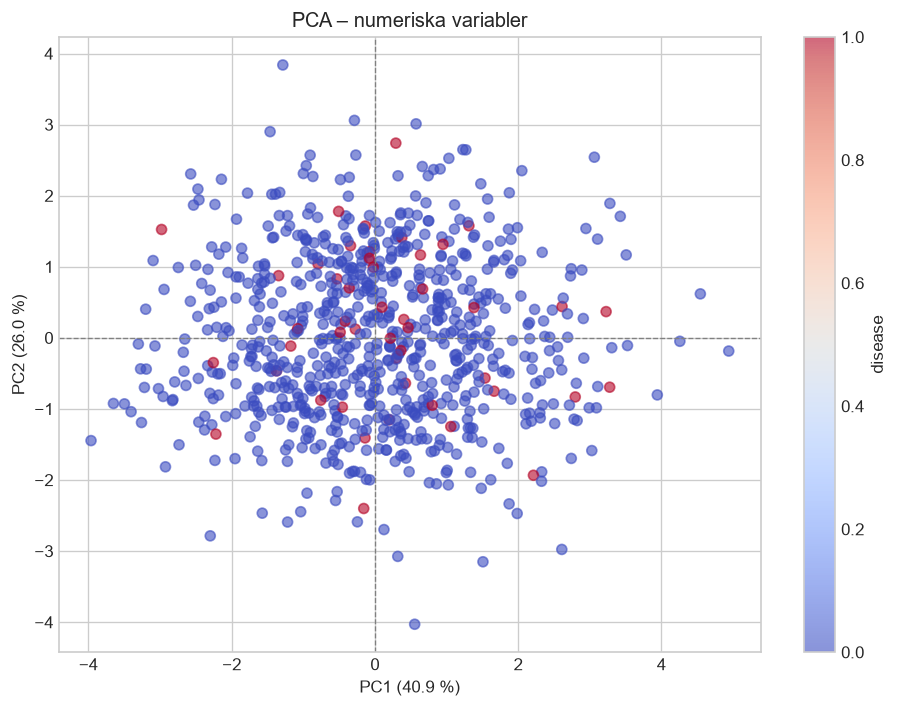

In [ ]:
# PCA Score Plot – 2D, färglagd efter sjukdomstatus
# Visualiserar personerna utifrån PC1 och PC2

# Varje punkt representerar en observation.
# Punkter nära varandra har liknande mönster
# i de variabler som ingår i PCA.

# Ett spridningsdiagram (scatterplot) med PC1 på x-axeln och PC2 på y-axeln

def plot_pca_2d_group(pca, X_pca, index, df_2d, titel, color_column="disease"):
    """ 
    Plots the PCA score plot in 2D, colored by a specified group
    """

    # Hämta färger från rätt observationer
    colors = df_2d.loc[index, color_column]
    explained_variance = pca.explained_variance_ratio_

    plt.figure(figsize=(8, 6))

    plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=colors,
        cmap="coolwarm",
        alpha=0.6
    )

    plt.axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
    plt.axvline(x=0, color="gray", linestyle="--", linewidth=0.8)

    plt.xlabel(f"PC1 ({explained_variance[0]*100:.1f} %)")
    plt.ylabel(f"PC2 ({explained_variance[1]*100:.1f} %)")

    plt.title(titel)

    plt.colorbar(label=color_column)

    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_pca_2d_group(
    pca_numeric, X_pca_numeric,
    index_numeric,
    df_pca,
    "PCA – numeriska variabler",
    color_column="disease"
)


**Tolkning:** PCA-analysen visar att PC1 och PC2 tillsammans förklarar 66,9 % av variationen i datamaterialet. De blå och röda punkterna är blandade och överlappar varandra. Det finns därför ingen tydlig skillnad mellan personer med och utan sjukdom. De numeriska variablerna verkar alltså inte visa någon större skillnad mellan grupperna.

#### Visualisering med tre huvudkomponenter

Scree-diagrammet visade att de tre första huvudkomponenterna kan vara mest intressant att undersöka. Tillsammans förklarar de 83,0 % av den totala variationen i datamaterialet. Med tre huvudkomponenterna behålls en stor del av informationen samtidigt som antalet dimensioner minskas ner. 

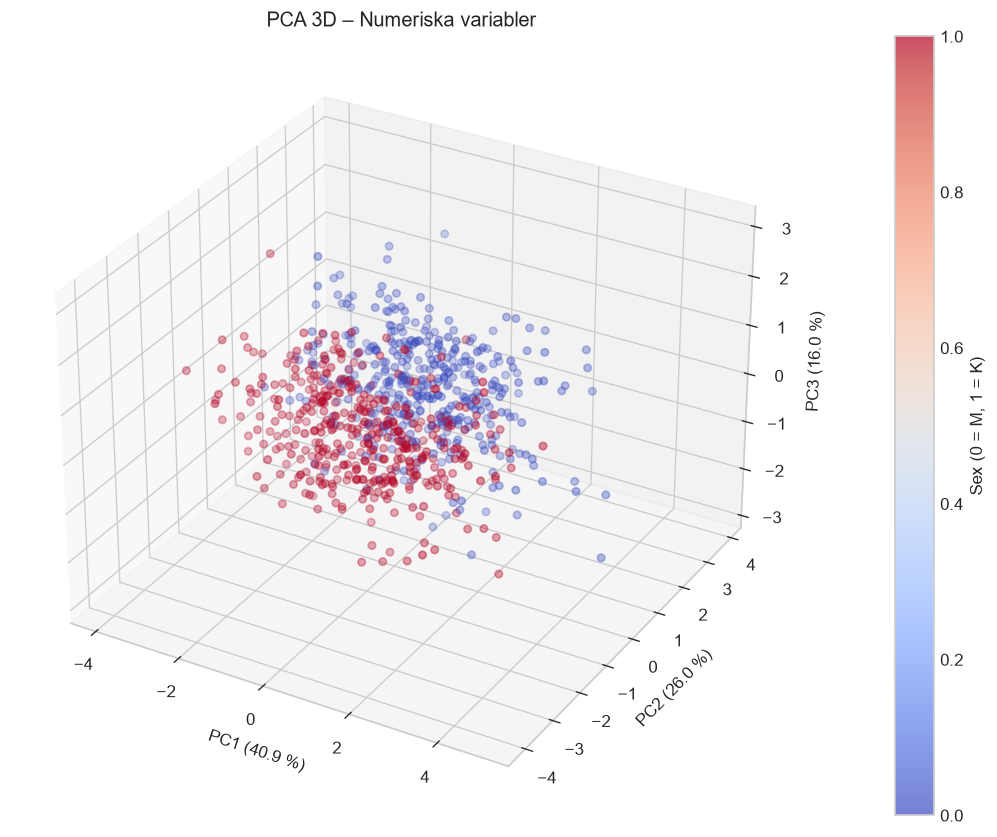

In [93]:
def plot_pca_3d(pca, X_pca, colors, titel, color_label):
    """ 
    Plots the PCA results in 3D
    """
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        X_pca[:, 2],
        c=colors,
        cmap="coolwarm",
        alpha=0.7
    )

    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)"
    )
    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)"
    )
    ax.set_zlabel(
        f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f} %)"
    )

    ax.set_title(titel)

    plt.colorbar(scatter, label=color_label, pad=0.10)
    plt.tight_layout()
    plt.show()

plot_pca_3d(
    pca_numeric,
    X_pca_numeric,
    df_pca.loc[index_numeric, "sex"],
    "PCA 3D – Numeriska variabler",
    "Sex (0 = M, 1 = K)"

)

# plot_pca_3d(
#     pca_numeric,
#     X_pca_numeric,
#     df_pca.loc[index_numeric, "smoker"],
#     "PCA 3D – Numeriska variabler",
#     "Smoker (0 = Nej, 1 = Ja)"

# )
# plot_pca_3d(
#     pca_numeric,
#     X_pca_numeric,
#     df_pca.loc[index_numeric, "disease"],
#     "PCA 3D – Numeriska variabler",
#     "Disease (0 = Nej, 1 = Ja)"

# )



När PCA-3D-diagrammet färgläggs efter kön framträder en uppdelning mellan män och kvinnor. Eftersom kön inte ingick som variabel i PCA-analysen så det kan den bero på skillnader i de numeriska variablerna mellan könen, exempelvis längd och vikt.

Detta stämmer med resultatet från loadings, som visar att PC1 främst påverkas av ålder, blodtryck och kolesterol. PC2 påverkas framför allt av längd och vikt, medan PC3 påverkas av flera variabler, bland annat längd, kolesterol och vikt. Där längd har ett positivt samband, men kolesterol och vikt har ett negativt samband.


Begränsningar
- PCA visar mönster och samband mellan variabler, men inte vad som orsakar vad. Ett positivt värde betyder alltså inte att en variabel orsakar en ökning av en annan.
- PCA-resultatet kan påverkas om rader med saknade värden tas bort. I det här datasetet har inga rader behövt tas bort.
- Variabler med olika skalor och enheter behöver standardiseras innan PCA genomförs. Annars kan variabler med större värden få för stor påverkan på resultatet.
- PCA bygger på linjära samband mellan variablerna. Om sambanden är mer komplicerade kan vissa mönster missas.
- Avvikande värden kan påverka resultatet och få stor betydelse för huvudkomponenterna.
- Ibland kan det vara svårtolkat vad en huvudkomponent egentligen innehåller, särskilt när flera variabler ingår ungefär lika mycket.